# Avaliação final: seleção, balanceamento, solução final, curva de aprendizado e teste

Este notebook fecha os itens obrigatórios do enunciado que faltavam depois dos notebooks 02 e 03. **Nada aqui usa o teste para escolher coisas**: todas as decisões saem da validação cruzada (3 dobras) nos 80% de desenvolvimento, com as mesmas dobras de sempre. O teste só é aberto na seção 9, com a solução já fixada.

| Seção | O que faz | Requisito do enunciado |
|---|---|---|
| 0 | Preparação, funções de apoio, histórico dos experimentos dos outros notebooks | Reprodutibilidade |
| 1 | Situação escolar: fusão aprendida só no treino x colunas separadas | Prevenção de vazamento; tratamento de categorias |
| 2 | UF da prova como feature | Aprofundamento (localização) |
| 3 | As 3 features criadas ajudam? | Engenharia de features (comparar com a representação inicial) |
| 4 | Seleção de atributos (`SelectKBest`) | Método de seleção; solução mais simples |
| 5 | Balanceamento por ponderação de faixas de nota | Balanceamento, efeito por faixa |
| 6 | Retirar um bloco de informação de cada vez | Aprofundamento (blocos) |
| 7 | Solução final, validação cruzada e comparação com baseline e regressão linear | Protocolo |
| 8 | Curva de aprendizado (10, 25, 50, 75 e 100% do treino da dobra) | Diagnóstico do ajuste |
| 9 | **Teste final** (uma única vez): métricas, resíduos, faixas e grupos | Avaliação |
| 10 | Figuras para o artigo (distribuição da nota, modelos antes/depois, PCA) | Artigo |

**Vazamento corrigido:** nos datasets 1 a 3 a `FUSAO_1` (média e desvio) e as medianas de `Q001` a `Q004` foram calculadas com todas as linhas. Aqui a `FUSAO_1` é refeita **dentro do Pipeline, só com o treino de cada dobra** (classe `FusaoSituacao`), a partir das 4 colunas originais. As medianas de `Q001` a `Q004` são números inteiros e são conferidas na seção 0 (a mediana do desenvolvimento é igual à de todas as linhas).

## 0. Preparação

A célula abaixo lê o `dataset_3_escola_features` (o maior dos datasets, com escola, `NÃO SEI`, nacionalidade e as 3 features criadas), tira dele a `FUSAO_1` (que vazava) e junta as 4 colunas originais da situação escolar e a UF da prova, lidas do arquivo bruto do Inep na mesma ordem dos ids. Fica **só com os 80% do desenvolvimento**; as linhas do teste ficam guardadas sem a nota até a seção 9.

Para testar o código rápido, rode com a variável de ambiente `SMOKE=1` (usa 30 mil pessoas e grava em outra pasta).

In [1]:
import os
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import PredefinedSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SMOKE = os.environ.get("SMOKE") == "1"                    # só para testar o código
ALVO = "NU_NOTA_MT"
SEMENTE = 42
PROC = Path("../dados/processed")
RES = Path(os.environ["SAIDA"]) if SMOKE else Path("../resultados")
FIG, TAB = RES / "figuras", RES / "tabelas"
MODELOS = RES / "models" if SMOKE else Path("../models")
for pasta in (FIG, TAB, MODELOS):
    pasta.mkdir(parents=True, exist_ok=True)

# quem está no desenvolvimento (80%) e a dobra (1, 2 ou 3) de cada pessoa: arquivos salvos em dados/splits/
ids = pd.read_csv(PROC / "ids_elegiveis.csv")["NU_INSCRICAO"]
em_dev = ids.isin(pd.read_csv("../dados/splits/desenvolvimento_ids.csv")["NU_INSCRICAO"]).to_numpy()
dobra_dev = pd.read_csv("../dados/splits/dobras_cv.csv")["dobra"].to_numpy()
assert len(dobra_dev) == em_dev.sum(), "dobras_cv.csv e desenvolvimento_ids.csv não combinam"

# colunas originais que a FUSAO_1 resume, mais a UF da prova (lidas do arquivo bruto, na ordem de ids_elegiveis.csv)
COLS_SITUACAO = ["IN_TREINEIRO", "TP_ANO_CONCLUIU", "TP_FAIXA_ETARIA", "TP_ST_CONCLUSAO"]
arq_extras = PROC / "extras_situacao_uf.csv"
if not arq_extras.exists():
    bruto = pd.read_csv("../dados/raw/DADOS/MICRODADOS_ENEM_2023.csv", sep=";", encoding="latin1",
                        usecols=["NU_INSCRICAO", "SG_UF_PROVA"] + COLS_SITUACAO).set_index("NU_INSCRICAO")
    bruto.loc[ids].reset_index().to_csv(arq_extras, index=False)
extras = pd.read_csv(arq_extras)
assert (extras["NU_INSCRICAO"].to_numpy() == ids.to_numpy()).all()

d3 = pd.read_csv(PROC / "dataset_3_escola_features.csv", usecols=lambda c: c not in (ALVO, "FUSAO_1")).astype("float32")
uf = pd.get_dummies(extras["SG_UF_PROVA"], prefix="UF", dtype="float32").drop(columns="UF_SP")     # referência: SP (a mais frequente)
UF_COLS = list(uf.columns)
BASE = list(d3.columns)                                                                               # 44 colunas sem a FUSAO_1
tudo = pd.concat([d3, extras[COLS_SITUACAO].astype("float32"), uf], axis=1)
NOVAS = ["PESSOAS_POR_QUARTO", "CELULAR_POR_MORADOR", "RENDA_MENOS_ESCOL"]                            # as 3 features criadas (notebook 01, seção 11c)
y_tudo = pd.read_csv(PROC / "dataset_3_escola_features.csv", usecols=[ALVO])[ALVO]
del d3, uf

rng = np.random.default_rng(SEMENTE)
X = tudo[em_dev].reset_index(drop=True)
y = y_tudo[em_dev].reset_index(drop=True)
X_teste = tudo[~em_dev].reset_index(drop=True)         # sem a nota; a nota do teste só é lida na seção 9
ids_teste = ids[~em_dev].reset_index(drop=True)
uf_teste = extras.loc[~em_dev, "SG_UF_PROVA"].reset_index(drop=True)
uf_dev = extras.loc[em_dev, "SG_UF_PROVA"].reset_index(drop=True)
del tudo, y_tudo

if SMOKE:                                              # amostra pequena só para testar o código
    amostra = np.sort(rng.choice(len(X), 30_000, replace=False))
    X, y, dobra_dev, uf_dev = X.iloc[amostra].reset_index(drop=True), y.iloc[amostra].reset_index(drop=True), dobra_dev[amostra], uf_dev.iloc[amostra].reset_index(drop=True)
    amostra_t = np.sort(rng.choice(len(X_teste), 5_000, replace=False))
    X_teste, ids_teste, uf_teste = X_teste.iloc[amostra_t].reset_index(drop=True), ids_teste.iloc[amostra_t].reset_index(drop=True), uf_teste.iloc[amostra_t].reset_index(drop=True)
else:
    amostra_t = None

dobras = PredefinedSplit(dobra_dev)

# conferência das medianas de Q001 a Q004 usadas no preenchimento do "não sei" (dataset 1): todas as linhas x só o desenvolvimento
fundidos = pd.read_csv(PROC / "dataset_1_fundido.csv", usecols=["Q001", "Q002", "Q003", "Q004"])
med_tudo = fundidos.median()
med_dev = fundidos[em_dev].median()
print("Mediana de Q001-Q004, todas as linhas :", med_tudo.to_dict())
print("Mediana de Q001-Q004, só desenvolvimento:", med_dev.to_dict(), "->", "iguais" if (med_tudo == med_dev).all() else "DIFERENTES")
del fundidos

print(f"\n{X.shape[0]:,} pessoas no desenvolvimento, {X.shape[1]} colunas (44 do dataset 3 sem FUSAO_1 + 4 de situação + {len(UF_COLS)} de UF)")
print(f"{X_teste.shape[0]:,} pessoas no teste (guardadas sem nota)")

Mediana de Q001-Q004, todas as linhas : {'Q001': 4.0, 'Q002': 4.0, 'Q003': 2.0, 'Q004': 1.0}
Mediana de Q001-Q004, só desenvolvimento: {'Q001': 4.0, 'Q002': 4.0, 'Q003': 2.0, 'Q004': 1.0} -> iguais

2,153,941 pessoas no desenvolvimento, 74 colunas (44 do dataset 3 sem FUSAO_1 + 4 de situação + 26 de UF)
538,486 pessoas no teste (guardadas sem nota)


### Funções de apoio

- `FusaoSituacao`: refaz a `FUSAO_1` **só com o treino** (média e desvio de cada uma das 4 colunas, aprendidos no `fit`). Segue a mesma receita do notebook 01: a coluna `TP_ANO_CONCLUIU = 0` ("não informado") vira ausente, `TP_ANO_CONCLUIU` e `TP_FAIXA_ETARIA` têm o sinal invertido, e a fusão é a média dos z-scores. Conferi que, com as estatísticas de todas as linhas, ela reproduz a `FUSAO_1` salva (erro máximo de 5e-6).
- `montar`: monta um `Pipeline` (fusão, padronização, seleção, regressor).
- `cv`: validação cruzada nas 3 dobras fixas. Treina em 2, valida na 3ª, e guarda **tudo por dobra** (RMSE, MAE, R², tempo e o erro por faixa de nota) em `resultados/experimentos.csv`. Se o experimento já foi feito, só lê o resultado salvo (para retomar sem refazer; `REFAZER = True` ignora isso).
- A conclusão de cada experimento é automática e honesta: só chamamos de melhora ou piora se a diferença do RMSE médio for maior que o desvio entre dobras da referência; senão é "sem diferença clara".

In [2]:
class FusaoSituacao(BaseEstimator, TransformerMixin):
    """Troca as 4 colunas de situação escolar por FUSAO_1, com média e desvio aprendidos só no treino."""
    colunas = COLS_SITUACAO
    sinais = np.array([1, -1, -1, 1])           # IN_TREINEIRO, TP_ANO_CONCLUIU, TP_FAIXA_ETARIA, TP_ST_CONCLUSAO

    def _z(self, X):
        z = X[self.colunas].astype("float64")
        z["TP_ANO_CONCLUIU"] = z["TP_ANO_CONCLUIU"].mask(z["TP_ANO_CONCLUIU"] == 0)     # 0 = "não informado" vira ausente
        return z

    def fit(self, X, y=None):
        z = self._z(X)
        self.media_, self.desvio_ = z.mean(), z.std()
        return self

    def transform(self, X):
        if not set(self.colunas) <= set(X.columns):                   # sem as 4 colunas (nos testes de blocos): não faz nada
            return X
        fusao = (((self._z(X) - self.media_) / self.desvio_) * self.sinais).mean(axis=1)
        saida = X.drop(columns=self.colunas)
        saida["FUSAO_1"] = fusao.to_numpy()
        return saida


def montar(regressor, fusao=False, padronizar=False, k=None):
    etapas = []
    if fusao:
        etapas.append(("fusao", FusaoSituacao()))
    if padronizar:
        etapas.append(("padroniza", StandardScaler()))
    if k:
        etapas.append(("selecao", SelectKBest(f_regression, k=k)))
    etapas.append(("regressor", regressor))
    return Pipeline(etapas)


def hgb_inicial():
    """Gradient Boosting de configuração inicial (o mesmo do notebook 02): usado nas comparações rápidas."""
    return HistGradientBoostingRegressor(learning_rate=0.1, max_iter=300, max_leaf_nodes=31, min_samples_leaf=200,
                                         early_stopping=True, validation_fraction=0.1, n_iter_no_change=10, random_state=SEMENTE)


# melhores hiperparâmetros da busca (notebook 02-treino-modelos-optimized, RandomizedSearchCV, 10 configurações, dataset_1_fundido)
PARAMS_BUSCA = dict(l2_regularization=0.24400607090817547, learning_rate=0.06689135590392836, max_iter=500,
                    max_leaf_nodes=89, min_samples_leaf=137)


def hgb_busca():
    return HistGradientBoostingRegressor(early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
                                         random_state=SEMENTE, **PARAMS_BUSCA)


FAIXAS = [-1, 0, 400, 500, 600, 700, 800, 1000]                    # faixas de nota fixadas no desenvolvimento (mesmas do notebook sem zeros)
ROT_FAIXAS = ["0", "1-400", "400-500", "500-600", "600-700", "700-800", "800+"]


def metricas(real, prev):
    return {"RMSE": mean_squared_error(real, prev) ** 0.5, "MAE": mean_absolute_error(real, prev), "R2": r2_score(real, prev)}


def por_faixa(real, prev, faixas=FAIXAS, rotulos=ROT_FAIXAS):
    """n, RMSE e viés (real - previsto; positivo = o modelo subestima) por faixa de nota."""
    d = pd.DataFrame({"faixa": pd.cut(np.asarray(real), faixas, labels=rotulos), "erro": np.asarray(real) - np.asarray(prev)})
    g = d.groupby("faixa", observed=False)["erro"]
    return pd.DataFrame({"n": g.size(), "RMSE": g.apply(lambda e: np.sqrt((e ** 2).mean()) if len(e) else np.nan), "vies": g.mean()})


COLUNAS_EXP = ["secao", "hipotese", "features", "preparacao", "modelo", "parametros", "avaliado", "n_features",
               "RMSE_d1", "RMSE_d2", "RMSE_d3", "MAE_d1", "MAE_d2", "MAE_d3", "R2_d1", "R2_d2", "R2_d3",
               "RMSE_media", "RMSE_desvio", "MAE_media", "MAE_desvio", "R2_media", "R2_desvio", "tempo_s", "conclusao"]
ARQ_EXP, ARQ_FAIXAS = RES / "experimentos.csv", TAB / "erros_por_faixa_cv.csv"
exp = pd.read_csv(ARQ_EXP, index_col="id") if ARQ_EXP.exists() else pd.DataFrame(columns=COLUNAS_EXP)
faixas_cv = pd.read_csv(ARQ_FAIXAS) if ARQ_FAIXAS.exists() else pd.DataFrame(columns=["id", "dobra", "faixa", "n", "RMSE", "vies"])
REFAZER = False


def gravar(id_exp, **linha):
    global exp
    exp.loc[id_exp] = pd.Series(linha).reindex(COLUNAS_EXP)
    exp.to_csv(ARQ_EXP, index_label="id")


def veredito(id_exp, ref):
    """Compara o RMSE médio com o da referência; só chama de melhora/piora se passar do desvio entre dobras."""
    dif = exp.loc[id_exp, "RMSE_media"] - exp.loc[ref, "RMSE_media"]
    lim = exp.loc[ref, "RMSE_desvio"]
    if abs(dif) <= lim:
        return f"RMSE {dif:+.3f} em relação a {ref}: sem diferença clara (dentro do desvio entre dobras, {lim:.3f})."
    return f"RMSE {dif:+.3f} em relação a {ref}: {'melhora' if dif < 0 else 'piora'} (maior que o desvio entre dobras, {lim:.3f})."


def cv(pipe, Xc, id_exp, secao, hipotese, preparacao, modelo, parametros, ref=None, peso=None):
    """Validação cruzada nas 3 dobras fixas; grava a linha em experimentos.csv. `peso` recebe as notas do treino da dobra e devolve pesos."""
    global faixas_cv
    if id_exp in exp.index and not REFAZER:
        r = exp.loc[id_exp]
        print(f"{id_exp}: já feito  RMSE {r['RMSE_media']:.3f} ± {r['RMSE_desvio']:.3f} | {r['conclusao']}")
        return r
    linhas, faixas = [], []
    for k, (tr, va) in enumerate(dobras.split(), 1):
        t0 = time.time()
        m = clone(pipe)
        ajuste = {} if peso is None else {m.steps[-1][0] + "__sample_weight": peso(y.iloc[tr].to_numpy())}
        m.fit(Xc.iloc[tr], y.iloc[tr], **ajuste)
        prev = m.predict(Xc.iloc[va])
        linhas.append({**metricas(y.iloc[va], prev), "tempo_s": time.time() - t0})
        f = por_faixa(y.iloc[va], prev).reset_index()
        f.insert(0, "dobra", k)
        f.insert(0, "id", id_exp)
        faixas.append(f)
    d = pd.DataFrame(linhas)
    linha = dict(secao=secao, hipotese=hipotese, features=f"{Xc.shape[1]} colunas", preparacao=preparacao, modelo=modelo,
                 parametros=parametros, avaliado="validação cruzada (3 dobras) no desenvolvimento", n_features=Xc.shape[1],
                 tempo_s=d["tempo_s"].mean())
    for m_ in ("RMSE", "MAE", "R2"):
        for k in range(3):
            linha[f"{m_}_d{k + 1}"] = d[m_][k]
        linha[f"{m_}_media"], linha[f"{m_}_desvio"] = d[m_].mean(), d[m_].std()
    gravar(id_exp, **linha, conclusao="")
    if ref is not None:
        exp.loc[id_exp, "conclusao"] = veredito(id_exp, ref)
        exp.to_csv(ARQ_EXP, index_label="id")
    faixas_cv = pd.concat([faixas_cv[faixas_cv["id"] != id_exp], *faixas], ignore_index=True)
    faixas_cv.to_csv(ARQ_FAIXAS, index=False)
    r = exp.loc[id_exp]
    print(f"{id_exp}: RMSE {r['RMSE_media']:.3f} ± {r['RMSE_desvio']:.3f} | MAE {r['MAE_media']:.3f} | R² {r['R2_media']:.3f} | "
          f"{r['tempo_s']:.0f} s por dobra | {r['conclusao']}")
    return r


def tabela(ids_exp, rotulos=None):
    t = exp.loc[ids_exp, ["n_features", "RMSE_media", "RMSE_desvio", "MAE_media", "R2_media", "tempo_s"]].astype(float).round(3)
    if rotulos:
        t.index = rotulos
    return t


def faixas_medias(id_exp):
    f = faixas_cv[faixas_cv["id"] == id_exp].groupby("faixa", observed=False)[["n", "RMSE", "vies"]].mean()
    return f.reindex(ROT_FAIXAS)

### Histórico dos notebooks anteriores

Para o `experimentos.csv` ficar completo, a célula abaixo registra os resultados dos notebooks 02, 02-optimized, 02-sem-zeros e 03. Os números foram **copiados das saídas desses notebooks** (só a média e o desvio, porque lá não guardamos as métricas por dobra) e, nas buscas, lidos de `resultados/tabelas/busca_*.csv`. Não rodam de novo aqui.

In [3]:
def hist(id_exp, secao, modelo, prep, parametros, rmse, desvio, mae, r2, tempo, conclusao, feats="30 colunas (dataset_1_fundido)", hip=""):
    if id_exp in exp.index:
        return
    gravar(id_exp, secao=secao, hipotese=hip, features=feats, preparacao=prep, modelo=modelo, parametros=parametros,
           avaliado="validação cruzada (3 dobras) no desenvolvimento",
           n_features=int(feats.split()[0]) if feats.split()[0].isdigit() else np.nan,
           RMSE_media=rmse, RMSE_desvio=desvio, MAE_media=mae, R2_media=r2, tempo_s=tempo, conclusao=conclusao)


# 1) configuração inicial de cada modelo (notebook 02-treino-modelos, seção 11), dataset_1_fundido
inicial = [("Baseline", "DummyRegressor(strategy='mean')", 131.634, 0.158, 107.582, -0.000, 0.059),
           ("Regressão linear", "StandardScaler + LinearRegression", 111.153, 0.178, 86.960, 0.287, 0.678),
           ("Ridge", "StandardScaler + Ridge(alpha=1)", 111.153, 0.178, 86.960, 0.287, 0.300),
           ("Árvore de decisão", "max_depth=10, min_samples_leaf=50", 110.551, 0.190, 86.381, 0.295, 2.973),
           ("KNN", "StandardScaler + k=50, brute", 111.575, 0.184, 87.180, 0.282, 476.276),
           ("SVR linear", "StandardScaler + LinearSVR(C=1)", 111.153, 0.178, 86.961, 0.287, 1.942),
           ("Bagging", "árvore max_depth=10; 20 estimadores; bootstrap", 110.014, 0.207, 85.991, 0.302, 24.135),
           ("Pasting", "árvore max_depth=10; 20 estimadores; max_samples=0.5", 110.012, 0.208, 85.996, 0.302, 19.845),
           ("Random Forest", "100 árvores, max_depth=12, max_features=0.5", 109.422, 0.195, 85.494, 0.309, 103.420),
           ("Gradient Boosting", "HistGB lr=0.1, max_iter=300, folhas=31", 107.770, 0.226, 83.825, 0.330, 132.725),
           ("Stacking", "Ridge + árvore + HistGB; final Ridge", 107.763, 0.226, 83.804, 0.330, 629.819)]
for nome, par, rmse, dp, mae, r2, t in inicial:
    hist(f"H_inicial_{nome}", "02 configuração inicial", nome, "padronização só nos modelos que precisam", par, rmse, dp, mae, r2, t,
         "Configuração inicial, antes das buscas.", hip="Comparar todos os regressores obrigatórios na mesma validação cruzada.")

# 2) depois da busca (RandomizedSearchCV, 10 configurações; melhor linha de cada busca_*.csv)
for arq, nome in [("gradient_boosting", "Gradient Boosting"), ("bagging", "Bagging"), ("random_forest", "Random Forest")]:
    busca_csv = Path("../resultados/tabelas") / f"busca_{arq}.csv"
    b = pd.read_csv(busca_csv).sort_values("RMSE").iloc[0] if busca_csv.exists() else None
    if b is not None:
        antes = exp.loc[f"H_inicial_{nome}", "RMSE_media"] if f"H_inicial_{nome}" in exp.index else np.nan
        hist(f"H_busca_{nome}", "02 depois da busca", nome, "igual à configuração inicial", str(b["parametros"]).replace("np.float64", ""),
             b["RMSE"], b["RMSE_desvio"], b["MAE"], b["R2"], b["tempo_s"], f"Depois da busca: RMSE {b['RMSE'] - antes:+.3f} em relação à configuração inicial.",
             hip="Os 3 melhores regressores distintos melhoram com RandomizedSearchCV (10 configurações).")

# 3) os 8 datasets (notebook 02, seção 12 e optimized): Regressão linear e Gradient Boosting / Bagging otimizado
datasets = [("dataset_1_fundido", 30, 111.153, 107.770), ("dataset_1_features", 33, 111.146, 107.759), ("dataset_2_escola", 34, 110.747, 107.261),
            ("dataset_2_features_escola", 37, 110.742, 107.255), ("dataset_3_sem_escola", 38, 110.752, 107.551),
            ("dataset_3_sem_escola_features", 41, 110.744, 107.540), ("dataset_3_escola", 42, 110.384, 107.056),
            ("dataset_3_escola_features", 45, 110.378, 107.048)]
for nome, n, rl, gb in datasets:
    hist(f"H_dataset_{nome}_GB", "02 comparação de datasets", "Gradient Boosting (inicial)", "FUSAO_1 e medianas com todas as linhas (vazamento leve)",
         "HistGB lr=0.1, max_iter=300, folhas=31", gb, np.nan, np.nan, np.nan, np.nan, "Comparação dos 8 datasets.", feats=f"{n} colunas ({nome})",
         hip="Escola, NÃO SEI/nacionalidade e as 3 features criadas acrescentam informação.")

# 4) treino sem as notas zero (notebook 02-sem-zeros) e PCA / K-means (notebook 03)
for nome, com, sem in [("Regressão linear", 111.153, 111.202), ("Ridge", 111.153, 111.202), ("Árvore de decisão", 110.337, 110.331), ("Gradient Boosting", 107.680, 107.737)]:
    hist(f"H_semzeros_{nome}", "02 sem zeros", nome, "notas 0 tiradas só do treino de cada dobra", "hiperparâmetros da busca", sem, np.nan, np.nan, np.nan, np.nan,
         f"RMSE {sem - com:+.3f} em relação ao treino com zeros: sem diferença clara.", hip="Tirar as 13.300 notas zero do treino reduz o erro nas outras faixas.")
pca = [("Regressão linear", "sem PCA", 111.153, 0.287), ("Regressão linear", "5", 114.425, 0.244), ("Regressão linear", "10", 113.047, 0.262),
       ("Regressão linear", "15", 112.718, 0.267), ("Regressão linear", "20", 111.887, 0.278), ("Regressão linear", "25", 111.658, 0.280),
       ("Gradient Boosting", "sem PCA", 107.770, 0.330), ("Gradient Boosting", "5", 113.210, 0.260), ("Gradient Boosting", "10", 111.551, 0.282),
       ("Gradient Boosting", "15", 111.148, 0.287), ("Gradient Boosting", "20", 110.432, 0.296), ("Gradient Boosting", "25", 110.165, 0.300)]
for nome, comp, rmse, r2 in pca:
    hist(f"H_pca_{nome}_{comp}", "03 PCA", nome, f"StandardScaler + PCA({comp}) dentro do Pipeline", f"componentes: {comp}", rmse, np.nan, np.nan, r2, np.nan,
         "PCA piora ou empata; 80% da variância exige 18 de 30 componentes." if comp != "sem PCA" else "Referência sem PCA.",
         hip="Reduzir a dimensão com PCA mantém o erro com menos colunas.")
hist("H_kmeans_Gradient Boosting", "03 K-means", "Gradient Boosting + distâncias aos 2 grupos", "MiniBatchKMeans(k=2) ajustado no treino", "k=2", 107.789, 0.232, 83.845, 0.329, 73.075,
     "RMSE +0.019 em relação ao Gradient Boosting sem as distâncias: sem diferença clara.", hip="Perfis semelhantes (clusters) acrescentam informação como features.")
print(f"experimentos.csv: {len(exp)} linhas ({(exp.index.str.startswith('H_')).sum()} do histórico)")

experimentos.csv: 39 linhas (39 do histórico)


### Distribuição da nota no desenvolvimento

O enunciado pede a distribuição da nota alvo identificando as notas zero. Elas são **0,62%** do desenvolvimento, são um resultado observado válido e ficam no treino e na validação (o notebook sem zeros mostrou que tirá-las do treino não muda o erro).

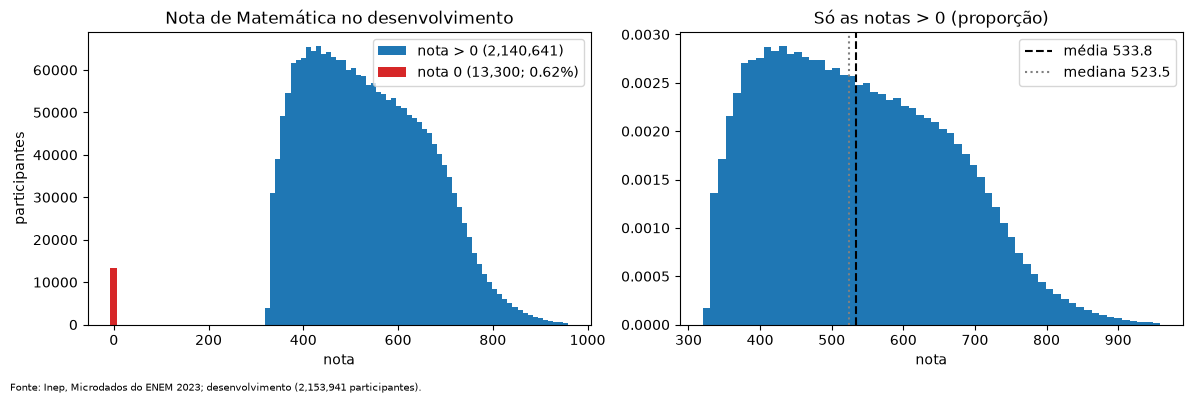

média 533.83 | mediana 523.50 | desvio 131.63 | zeros 13,300


In [4]:
zeros = int((y == 0).sum())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(y[y > 0], bins=60, color="tab:blue", label=f"nota > 0 ({len(y) - zeros:,})")
ax[0].bar([0], [zeros], width=14, color="tab:red", label=f"nota 0 ({zeros:,}; {zeros / len(y):.2%})")
ax[0].set_title("Nota de Matemática no desenvolvimento")
ax[0].set_xlabel("nota")
ax[0].set_ylabel("participantes")
ax[0].legend()
ax[1].hist(y[y > 0], bins=60, density=True, color="tab:blue")
ax[1].axvline(y.mean(), color="black", ls="--", label=f"média {y.mean():.1f}")
ax[1].axvline(y.median(), color="gray", ls=":", label=f"mediana {y.median():.1f}")
ax[1].set_title("Só as notas > 0 (proporção)")
ax[1].set_xlabel("nota")
ax[1].legend()
fig.text(0.01, 0.01, f"Fonte: Inep, Microdados do ENEM 2023; desenvolvimento ({len(y):,} participantes).", fontsize=7)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG / "distribuicao_nota_dev.png", dpi=150)
plt.show()
print(f"média {y.mean():.2f} | mediana {y.median():.2f} | desvio {y.std():.2f} | zeros {zeros:,}")

## 1. Situação escolar: fusão aprendida só no treino x colunas separadas

**Hipótese 1.** Fundir as 4 colunas de situação escolar numa só (`FUSAO_1`) joga fora informação: manter as 4 colunas separadas diminui o RMSE. (Um teste lateral anterior já sugeria isso, com ganho de uns 0,5 ponto no RMSE; aqui o teste fica documentado e o vazamento da fusão é corrigido.)

- **1a:** `FusaoSituacao` dentro do Pipeline (média e desvio só do treino da dobra).
- **1b:** as 4 colunas originais separadas, sem fusão.

As duas usam o Gradient Boosting de configuração inicial, as 44 colunas do dataset 3 (sem a fusão que vazava) e as mesmas dobras. Escolhemos a de menor RMSE médio.

In [5]:
COLS_REP = BASE + COLS_SITUACAO
H1 = "Fundir as 4 colunas de situação escolar numa só perde informação; mantê-las separadas diminui o RMSE."
a = cv(montar(hgb_inicial(), fusao=True), X[COLS_REP], "S1a_fusao_no_treino", "1 situação escolar", H1,
       "FUSAO_1 refeita só com o treino de cada dobra", "HistGradientBoosting (configuração inicial)", "lr=0.1, max_iter=300, folhas=31, leaf=200")
b = cv(montar(hgb_inicial(), fusao=False), X[COLS_REP], "S1b_colunas_separadas", "1 situação escolar", H1,
       "4 colunas originais separadas, sem fusão", "HistGradientBoosting (configuração inicial)", "lr=0.1, max_iter=300, folhas=31, leaf=200", ref="S1a_fusao_no_treino")
FUSAO = bool(a["RMSE_media"] <= b["RMSE_media"])
ID_SIT = "S1a_fusao_no_treino" if FUSAO else "S1b_colunas_separadas"
print(f"\nEscolhido: {'fusão no treino' if FUSAO else '4 colunas separadas'} ({ID_SIT}).")
tabela(["S1a_fusao_no_treino", "S1b_colunas_separadas"], ["1a fusão (treino da dobra)", "1b colunas separadas"])

S1a_fusao_no_treino: RMSE 107.051 ± 0.192 | MAE 83.161 | R² 0.339 | 25 s por dobra | 


S1b_colunas_separadas: RMSE 106.726 ± 0.189 | MAE 82.841 | R² 0.343 | 27 s por dobra | RMSE -0.325 em relação a S1a_fusao_no_treino: melhora (maior que o desvio entre dobras, 0.192).

Escolhido: 4 colunas separadas (S1b_colunas_separadas).


,n_features,RMSE_media,RMSE_desvio,MAE_media,R2_media,tempo_s
1a fusão (treino da dobra),48.0,107.051,0.192,83.161,0.339,24.609
1b colunas separadas,48.0,106.726,0.189,82.841,0.343,27.075


## 2. UF da prova

**Hipótese 2 (localização).** O estado da prova acrescenta informação que o perfil não tem (rede de ensino, custo de vida, desigualdade regional) e diminui o RMSE. A UF entra como 26 colunas 0/1 (referência: SP). É a UF **onde a pessoa fez a prova**, não onde mora; os códigos são fixos (27 estados), então nada é aprendido dos dados.

In [6]:
COLS_UF = COLS_REP + UF_COLS
c = cv(montar(hgb_inicial(), fusao=FUSAO), X[COLS_UF], "S2_com_uf", "2 localização",
       "O estado da prova acrescenta informação de contexto e diminui o RMSE.",
       f"{'FUSAO_1 no treino' if FUSAO else '4 colunas separadas'} + 26 colunas de UF (referência SP)", "HistGradientBoosting (configuração inicial)",
       "lr=0.1, max_iter=300, folhas=31, leaf=200", ref=ID_SIT)
USAR_UF = bool(c["RMSE_media"] < exp.loc[ID_SIT, "RMSE_media"])
COLS = COLS_UF if USAR_UF else COLS_REP
ID_REP = "S2_com_uf" if USAR_UF else ID_SIT
print(f"\nUF {'entra' if USAR_UF else 'não entra'} na representação final ({len(COLS)} colunas). Referência das próximas comparações: {ID_REP}.")
tabela([ID_SIT, "S2_com_uf"], ["sem UF", "com UF"])

S2_com_uf: RMSE 106.025 ± 0.188 | MAE 82.196 | R² 0.351 | 40 s por dobra | RMSE -0.701 em relação a S1b_colunas_separadas: melhora (maior que o desvio entre dobras, 0.189).

UF entra na representação final (74 colunas). Referência das próximas comparações: S2_com_uf.


,n_features,RMSE_media,RMSE_desvio,MAE_media,R2_media,tempo_s
sem UF,48.0,106.726,0.189,82.841,0.343,27.075
com UF,74.0,106.025,0.188,82.196,0.351,39.934


## 3. As 3 features criadas ajudam?

**Hipótese 3.** As 3 features criadas na engenharia (`PESSOAS_POR_QUARTO`, `CELULAR_POR_MORADOR`, `RENDA_MENOS_ESCOL`) acrescentam sinal que as colunas originais não têm. Comparamos a **representação inicial** (sem elas) com a representação com elas, no mesmo modelo e nas mesmas dobras.

In [7]:
COLS_SEM = [c for c in COLS if c not in NOVAS]
d_ = cv(montar(hgb_inicial(), fusao=FUSAO), X[COLS_SEM], "S3_sem_features_criadas", "3 features criadas",
        "As 3 features criadas acrescentam sinal além das colunas originais.", "mesma representação, sem as 3 colunas criadas",
        "HistGradientBoosting (configuração inicial)", "lr=0.1, max_iter=300, folhas=31, leaf=200", ref=ID_REP)
print("\nAs 3 criadas (com) x representação inicial (sem):")
tabela([ID_REP, "S3_sem_features_criadas"], ["com as 3 criadas", "sem as criadas (inicial)"])

S3_sem_features_criadas: RMSE 106.038 ± 0.167 | MAE 82.209 | R² 0.351 | 38 s por dobra | RMSE +0.013 em relação a S2_com_uf: sem diferença clara (dentro do desvio entre dobras, 0.188).

As 3 criadas (com) x representação inicial (sem):


,n_features,RMSE_media,RMSE_desvio,MAE_media,R2_media,tempo_s
com as 3 criadas,74.0,106.025,0.188,82.196,0.351,39.934
sem as criadas (inicial),71.0,106.038,0.167,82.209,0.351,37.902


## 4. Seleção de atributos: `SelectKBest` com teste F

**Método.** `SelectKBest(f_regression, k)` dá a cada coluna uma nota (teste F da correlação linear com a nota) e fica com as `k` maiores. **Roda dentro do Pipeline**, então as notas são recalculadas só com o treino de cada dobra. `f_regression` é rápido nos 2 milhões de linhas e mede só relação linear; por isso também mostramos a importância por permutação do modelo final na seção 7.

**Hipótese 4 (solução mais simples).** Dá para manter o RMSE com menos colunas (e menos tempo). Testamos `k` = 30%, 50% e 70% das colunas, no Gradient Boosting e na regressão linear. Regra de escolha, decidida antes de ver os resultados: o **menor `k` cujo RMSE médio fica dentro de 1 desvio entre dobras do RMSE da representação completa**; se nenhum, usamos todas as colunas.

In [8]:
KS = sorted({int(len(COLS) * f) for f in (0.3, 0.5, 0.7)})
H4 = "Dá para manter o RMSE com menos colunas: SelectKBest(f_regression) com k menor."
for k in KS:
    cv(montar(hgb_inicial(), fusao=FUSAO, k=k), X[COLS], f"S4_gb_k{k}", "4 seleção de atributos", H4,
       f"{'FUSAO_1 no treino; ' if FUSAO else ''}SelectKBest(f_regression, k={k}) no Pipeline", "HistGradientBoosting (configuração inicial)",
       f"k={k}; lr=0.1, max_iter=300, folhas=31", ref=ID_REP)
# regressão linear: padroniza -> (seleciona) -> LinearRegression
cv(montar(LinearRegression(), fusao=FUSAO, padronizar=True), X[COLS], "S4_linear_todas", "4 seleção de atributos", H4,
   "padronização; todas as colunas", "LinearRegression (sem regularização)", "sem hiperparâmetros")
for k in KS:
    cv(montar(LinearRegression(), fusao=FUSAO, padronizar=True, k=k), X[COLS], f"S4_linear_k{k}", "4 seleção de atributos", H4,
       f"padronização; SelectKBest(f_regression, k={k})", "LinearRegression (sem regularização)", f"k={k}", ref="S4_linear_todas")

ids_gb = [ID_REP] + [f"S4_gb_k{k}" for k in KS]
ids_lin = ["S4_linear_todas"] + [f"S4_linear_k{k}" for k in KS]
sel = pd.concat([tabela(ids_gb, ["todas"] + [f"k={k}" for k in KS]).add_prefix("GB "), tabela(ids_lin, ["todas"] + [f"k={k}" for k in KS]).add_prefix("Linear ")], axis=1)
sel[["GB RMSE_media", "GB RMSE_desvio", "GB tempo_s", "Linear RMSE_media", "Linear RMSE_desvio"]]

S4_gb_k22: RMSE 110.607 ± 0.191 | MAE 86.359 | R² 0.294 | 14 s por dobra | RMSE +4.582 em relação a S2_com_uf: piora (maior que o desvio entre dobras, 0.188).


S4_gb_k37: RMSE 107.436 ± 0.208 | MAE 83.451 | R² 0.334 | 24 s por dobra | RMSE +1.412 em relação a S2_com_uf: piora (maior que o desvio entre dobras, 0.188).


S4_gb_k51: RMSE 107.069 ± 0.199 | MAE 83.114 | R² 0.338 | 30 s por dobra | RMSE +1.044 em relação a S2_com_uf: piora (maior que o desvio entre dobras, 0.188).


S4_linear_todas: RMSE 108.868 ± 0.162 | MAE 84.862 | R² 0.316 | 2 s por dobra | 


S4_linear_k22: RMSE 112.251 ± 0.165 | MAE 88.012 | R² 0.273 | 1 s por dobra | RMSE +3.382 em relação a S4_linear_todas: piora (maior que o desvio entre dobras, 0.162).


S4_linear_k37: RMSE 110.526 ± 0.198 | MAE 86.260 | R² 0.295 | 1 s por dobra | RMSE +1.657 em relação a S4_linear_todas: piora (maior que o desvio entre dobras, 0.162).


S4_linear_k51: RMSE 110.198 ± 0.196 | MAE 85.952 | R² 0.299 | 1 s por dobra | RMSE +1.329 em relação a S4_linear_todas: piora (maior que o desvio entre dobras, 0.162).


,GB RMSE_media,GB RMSE_desvio,GB tempo_s,Linear RMSE_media,Linear RMSE_desvio
todas,106.025,0.188,39.934,108.868,0.162
k=22,110.607,0.191,14.243,112.251,0.165
k=37,107.436,0.208,23.518,110.526,0.198
k=51,107.069,0.199,29.879,110.198,0.196


Limite = 106.213. k dentro do limite: []. Escolhido: todas as colunas.


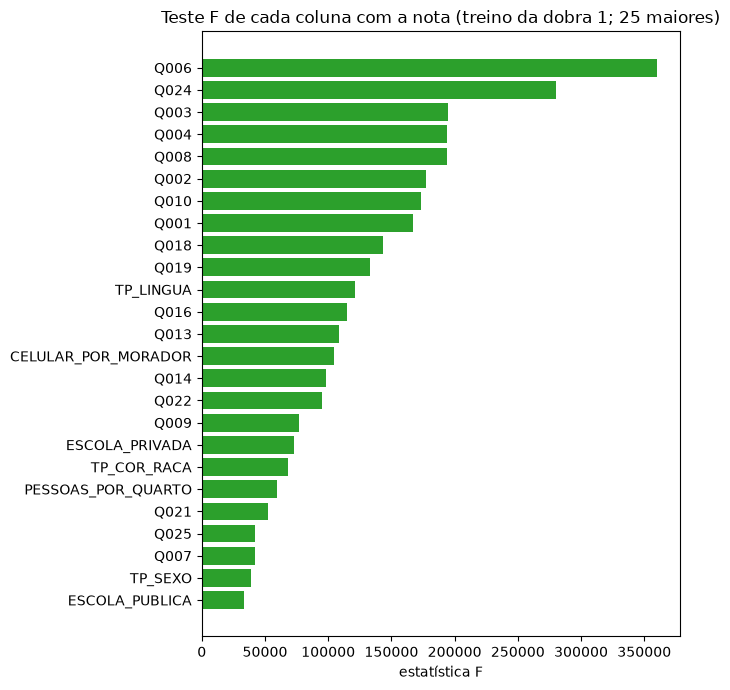

Menores notas F (candidatas a sair): {'UF_GO': 4.5, 'NAC_ESTRANGEIRO': 13.9, 'UF_MS': 41.4, 'UF_RR': 47.7, 'NAC_NAO_INFORMADO': 107.3, 'UF_RN': 171.0, 'UF_PE': 275.4, 'TP_ST_CONCLUSAO': 284.2}


In [9]:
# regra decidida antes: menor k dentro de 1 desvio da representação completa
limite = exp.loc[ID_REP, "RMSE_media"] + exp.loc[ID_REP, "RMSE_desvio"]
ok = [k for k in KS if exp.loc[f"S4_gb_k{k}", "RMSE_media"] <= limite]
K = min(ok) if ok else None
print(f"Limite = {limite:.3f}. k dentro do limite: {ok}. Escolhido: {'todas as colunas' if K is None else f'k={K}'}.")

# quais colunas o teste F escolheria (treino da dobra 1) e o que ele mede
tr1, _ = next(iter(dobras.split()))
Xtr1 = X[COLS].iloc[tr1]
Xf = FusaoSituacao().fit(Xtr1).transform(Xtr1) if FUSAO else Xtr1
f_val, _ = f_regression(Xf, y.iloc[tr1])
notas_f = pd.Series(f_val, index=Xf.columns).sort_values()
plt.figure(figsize=(7, 7))
plt.barh(notas_f.tail(25).index, notas_f.tail(25).values, color=["tab:green" if c in notas_f.tail(K or len(COLS)).index else "lightgray" for c in notas_f.tail(25).index])
plt.title("Teste F de cada coluna com a nota (treino da dobra 1; 25 maiores)")
plt.xlabel("estatística F")
plt.tight_layout()
plt.savefig(FIG / "selecao_teste_f.png", dpi=150)
plt.show()
print("Menores notas F (candidatas a sair):", notas_f.head(8).round(1).to_dict())

## 5. Balanceamento: ponderação por faixa de nota

**Problema.** As notas muito baixas e muito altas são raras e o modelo erra mais nelas (ele "puxa" tudo para o meio). **Estratégia: ponderação** (`sample_weight` do Gradient Boosting). As linhas do treino são agrupadas em **faixas de 50 pontos** (a nota 0 numa faixa própria) e cada linha recebe peso `(pessoas na faixa)^(-α)`, normalizado para média 1. Os pesos usam **só as notas do treino da dobra**; a validação mantém a distribuição original, e o alvo continua sendo a nota numérica.

- **α = 0,5:** peso moderado (raiz do inverso da frequência).
- **α = 1,0:** peso pelo inverso da frequência (equilibra todas as faixas).

**Hipótese 5.** Dar mais peso às faixas raras reduz o erro nelas, talvez à custa do erro geral. Adotamos a ponderação só se o RMSE médio geral ficar **menor** que o do mesmo modelo sem pesos.

In [10]:
def pesos_por_faixa(alpha, largura=50):
    def f(y_treino):
        faixa = np.where(y_treino == 0, -1, (y_treino // largura).astype(int))
        n = pd.Series(faixa).map(pd.Series(faixa).value_counts()).to_numpy().astype(float)
        w = n ** (-alpha)
        return w / w.mean()
    return f


H5 = "Ponderar as faixas raras de nota reduz o erro nelas; o erro geral pode piorar."
for alpha in (0.5, 1.0):
    cv(montar(hgb_inicial(), fusao=FUSAO, k=K), X[COLS], f"S5_peso_alfa_{alpha}", "5 balanceamento", H5,
       f"pesos por faixa de 50 pontos, peso = n^(-{alpha}), calculados só no treino da dobra", "HistGradientBoosting (configuração inicial)",
       f"alpha={alpha}", ref=ID_REP if K is None else f"S4_gb_k{K}", peso=pesos_por_faixa(alpha))
ID_SEM_PESO = ID_REP if K is None else f"S4_gb_k{K}"
cand = {a: exp.loc[f"S5_peso_alfa_{a}", "RMSE_media"] for a in (0.5, 1.0)}
ALFA = min(cand, key=cand.get) if min(cand.values()) < exp.loc[ID_SEM_PESO, "RMSE_media"] else None
print(f"\nPonderação {'adotada com alpha=' + str(ALFA) if ALFA else 'NÃO adotada: nenhum alpha reduz o RMSE médio geral'}.")
tabela([ID_SEM_PESO, "S5_peso_alfa_0.5", "S5_peso_alfa_1.0"], ["sem pesos", "α = 0,5", "α = 1,0"])

S5_peso_alfa_0.5: RMSE 108.140 ± 0.188 | MAE 82.820 | R² 0.325 | 40 s por dobra | RMSE +2.115 em relação a S2_com_uf: piora (maior que o desvio entre dobras, 0.188).


S5_peso_alfa_1.0: RMSE 123.459 ± 0.149 | MAE 94.826 | R² 0.120 | 24 s por dobra | RMSE +17.434 em relação a S2_com_uf: piora (maior que o desvio entre dobras, 0.188).

Ponderação NÃO adotada: nenhum alpha reduz o RMSE médio geral.


,n_features,RMSE_media,RMSE_desvio,MAE_media,R2_media,tempo_s
sem pesos,74.0,106.025,0.188,82.196,0.351,39.934
"α = 0,5",74.0,108.140,0.188,82.820,0.325,40.329
"α = 1,0",74.0,123.459,0.149,94.826,0.120,24.324


RMSE e viés (real - previsto) por faixa de nota, média das 3 dobras:
        pessoas (média/dobra) RMSE sem pesos RMSE α = 0,5 RMSE α = 1,0 viés sem pesos viés α = 0,5 viés α = 1,0
faixa                                                                                                          
0                      4433.0          513.8        510.4        489.5         -509.1       -503.3       -475.4
1-400                111778.0          122.6        120.1        112.2         -109.2        -99.9        -67.7
400-500              198921.0           78.8         85.3        100.6          -50.2        -44.6        -18.1
500-600              175776.0           66.8         80.6        115.6           18.3         17.7         33.0
600-700              144449.0          100.3        105.5        134.7           74.6         63.7         58.9
700-800               67509.0          134.9        125.7        135.2          116.7         91.9         62.3
800+                  15114.0      

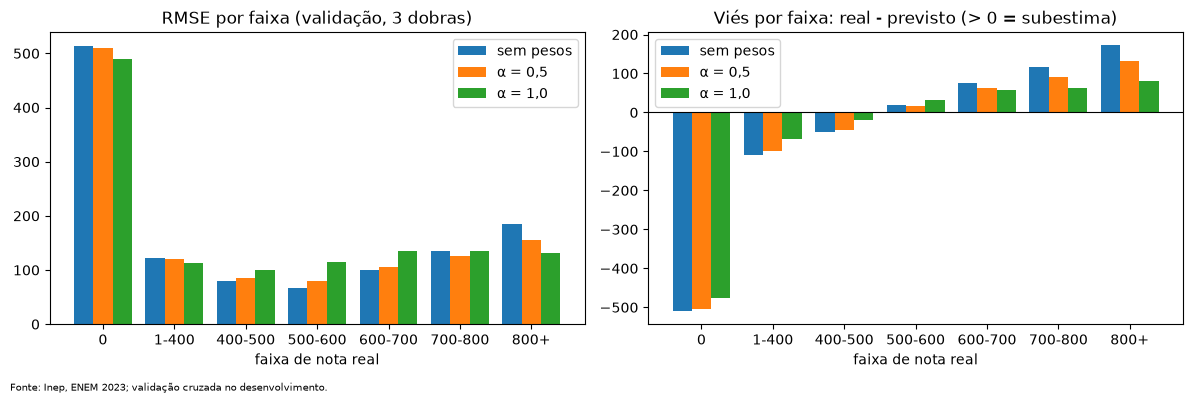

In [11]:
# erro por faixa de nota (média das 3 dobras): com e sem pesos
comp = pd.concat({"sem pesos": faixas_medias(ID_SEM_PESO), "α = 0,5": faixas_medias("S5_peso_alfa_0.5"), "α = 1,0": faixas_medias("S5_peso_alfa_1.0")}, axis=1)
resumo = pd.DataFrame({"pessoas (média/dobra)": comp[("sem pesos", "n")].round(0)})
for nome in ("sem pesos", "α = 0,5", "α = 1,0"):
    resumo[f"RMSE {nome}"] = comp[(nome, "RMSE")].round(1)
for nome in ("sem pesos", "α = 0,5", "α = 1,0"):
    resumo[f"viés {nome}"] = comp[(nome, "vies")].round(1)
resumo.to_csv(TAB / "balanceamento_por_faixa.csv")
print("RMSE e viés (real - previsto) por faixa de nota, média das 3 dobras:")
print(resumo.to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(ROT_FAIXAS))
for i, nome in enumerate(("sem pesos", "α = 0,5", "α = 1,0")):
    ax[0].bar(x + (i - 1) * 0.27, comp[(nome, "RMSE")], 0.27, label=nome)
    ax[1].bar(x + (i - 1) * 0.27, comp[(nome, "vies")], 0.27, label=nome)
for a_ in ax:
    a_.set_xticks(x, ROT_FAIXAS)
    a_.set_xlabel("faixa de nota real")
    a_.legend()
ax[0].set_title("RMSE por faixa (validação, 3 dobras)")
ax[1].set_title("Viés por faixa: real - previsto (> 0 = subestima)")
ax[1].axhline(0, color="black", lw=0.8)
fig.text(0.01, 0.01, "Fonte: Inep, ENEM 2023; validação cruzada no desenvolvimento.", fontsize=7)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG / "balanceamento_por_faixa.png", dpi=150)
plt.show()

## 6. Quanto vale cada bloco de informação?

**Hipótese 6.** Cada bloco de colunas contribui para o erro. Tiramos **um bloco de cada vez** da representação atual, com o mesmo modelo e as mesmas dobras, e medimos quanto o RMSE sobe. Blocos: renda; escolaridade e ocupação dos responsáveis; bens e domicílio; escola; localização (UF, se estiver em uso); perfil e trajetória (sexo, idade, situação escolar, cor/raça, língua, nacionalidade).

Mesma regra de leitura: só é diferença se passa do desvio entre dobras.

S6_sem_renda: RMSE 106.893 ± 0.194 | MAE 83.034 | R² 0.341 | 44 s por dobra | RMSE +0.868 em relação a S2_com_uf: piora (maior que o desvio entre dobras, 0.188).


S6_sem_escolaridade: RMSE 106.559 ± 0.168 | MAE 82.713 | R² 0.345 | 46 s por dobra | RMSE +0.534 em relação a S2_com_uf: piora (maior que o desvio entre dobras, 0.188).


S6_sem_bens: RMSE 107.356 ± 0.174 | MAE 83.392 | R² 0.335 | 33 s por dobra | RMSE +1.331 em relação a S2_com_uf: piora (maior que o desvio entre dobras, 0.188).


S6_sem_escola: RMSE 106.439 ± 0.185 | MAE 82.564 | R² 0.346 | 47 s por dobra | RMSE +0.414 em relação a S2_com_uf: piora (maior que o desvio entre dobras, 0.188).


S6_sem_localização: RMSE 106.726 ± 0.189 | MAE 82.841 | R² 0.343 | 33 s por dobra | RMSE +0.701 em relação a S2_com_uf: piora (maior que o desvio entre dobras, 0.188).


S6_sem_perfil: RMSE 110.445 ± 0.189 | MAE 86.236 | R² 0.296 | 35 s por dobra | RMSE +4.420 em relação a S2_com_uf: piora (maior que o desvio entre dobras, 0.188).


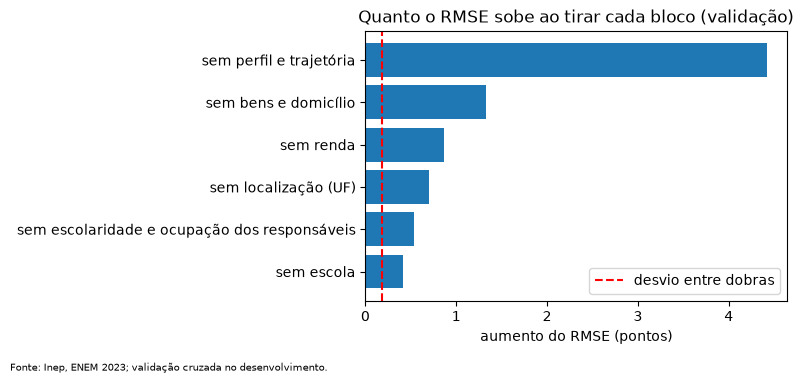

,n_features,RMSE_media,RMSE_desvio,MAE_media,R2_media,tempo_s,sobe_RMSE
completa,74.0,106.025,0.188,82.196,0.351,39.934,0.000
sem renda,72.0,106.893,0.194,83.034,0.341,43.631,0.868
sem escolaridade e ocupação dos responsáveis,66.0,106.559,0.168,82.713,0.345,46.325,0.534
sem bens e domicílio,52.0,107.356,0.174,83.392,0.335,32.526,1.331
sem escola,70.0,106.439,0.185,82.564,0.346,46.792,0.414
sem localização (UF),48.0,106.726,0.189,82.841,0.343,32.544,0.701
sem perfil e trajetória,62.0,110.445,0.189,86.236,0.296,34.629,4.420


In [12]:
QS = [f"Q{n:03d}" for n in range(7, 26)]
BLOCOS = {
    "renda": ["Q006", "RENDA_MENOS_ESCOL"],
    "escolaridade e ocupação dos responsáveis": ["Q001", "Q002", "Q003", "Q004", "Q001_NAO_SEI", "Q002_NAO_SEI", "Q003_NAO_SEI", "Q004_NAO_SEI"],
    "bens e domicílio": ["Q005"] + QS + ["PESSOAS_POR_QUARTO", "CELULAR_POR_MORADOR"],
    "escola": ["ESCOLA_PUBLICA", "ESCOLA_PRIVADA", "LOC_URBANA", "LOC_RURAL"],
    "localização (UF)": UF_COLS,
    "perfil e trajetória": ["TP_SEXO", "TP_ESTADO_CIVIL", "TP_COR_RACA", "TP_LINGUA", "NAC_NAO_INFORMADO", "NAC_NATURALIZADO",
                            "NAC_ESTRANGEIRO", "NAC_NATO_EXTERIOR"] + COLS_SITUACAO,
}
assert sorted(sum(BLOCOS.values(), [])) == sorted(BASE + COLS_SITUACAO + UF_COLS), "os blocos não cobrem as colunas exatamente"
H6 = "Cada bloco de informação contribui; tirar um de cada vez mostra quanto ele vale."
ids_blocos = {}
for nome, cols in BLOCOS.items():
    resto = [c for c in COLS if c not in cols]
    if len(resto) == len(COLS):
        continue                                                   # bloco que não está na representação (ex.: UF fora)
    ids_blocos[nome] = f"S6_sem_{nome.split(' ')[0]}"
    cv(montar(hgb_inicial(), fusao=FUSAO), X[resto], ids_blocos[nome], "6 blocos de informação", H6,
       f"representação atual sem o bloco '{nome}' ({len(cols)} colunas)", "HistGradientBoosting (configuração inicial)",
       "lr=0.1, max_iter=300, folhas=31, leaf=200", ref=ID_REP)

blocos = tabela([ID_REP] + list(ids_blocos.values()), ["completa"] + [f"sem {n}" for n in ids_blocos])
blocos["sobe_RMSE"] = blocos["RMSE_media"] - blocos.loc["completa", "RMSE_media"]
blocos.to_csv(TAB / "blocos_de_informacao.csv")
ordem = blocos.drop(index="completa").sort_values("sobe_RMSE")
plt.figure(figsize=(8, 3.8))
plt.barh(ordem.index, ordem["sobe_RMSE"], color="tab:blue")
plt.axvline(exp.loc[ID_REP, "RMSE_desvio"], color="red", ls="--", label="desvio entre dobras")
plt.title("Quanto o RMSE sobe ao tirar cada bloco (validação)")
plt.xlabel("aumento do RMSE (pontos)")
plt.legend()
plt.figtext(0.01, 0.01, "Fonte: Inep, ENEM 2023; validação cruzada no desenvolvimento.", fontsize=7)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig(FIG / "blocos_de_informacao.png", dpi=150)
plt.show()
blocos.round(3)

## 7. Solução final e validação cruzada

A solução final junta tudo o que ganhou na validação cruzada: a representação decidida nas seções 1 a 3, a seleção (se houve), a ponderação (se houve) e o **Gradient Boosting com os melhores hiperparâmetros da busca** (notebook `02-treino-modelos-optimized`: `learning_rate`≈0,067, `max_iter`=500, `max_leaf_nodes`=89, `min_samples_leaf`=137, `l2_regularization`≈0,24). A busca foi feita no `dataset_1_fundido`; reaproveitamos os hiperparâmetros na representação final (reajustar a busca de novo custaria 75 minutos, e a escolha final é sustentada pela validação cruzada abaixo).

Aqui também ficam as referências obrigatórias na mesma representação: **baseline pela média** e **regressão linear sem regularização**.

In [13]:
def pipe_final():
    return montar(hgb_busca(), fusao=FUSAO, k=K)


PESO_FINAL = pesos_por_faixa(ALFA) if ALFA else None
DESC_PREP = (f"{'FUSAO_1 refeita no treino' if FUSAO else '4 colunas de situação separadas'}; UF {'sim' if USAR_UF else 'não'}; "
             f"3 features criadas; seleção {'SelectKBest k=' + str(K) if K else 'nenhuma'}; "
             f"pesos {'α=' + str(ALFA) if ALFA else 'nenhum'}")
print("Solução final:", DESC_PREP)

cv(montar(DummyRegressor(strategy="mean")), X[COLS], "F_baseline_cv", "7 solução final", "Referência: baseline pela média.", "nenhuma",
   "DummyRegressor(strategy='mean')", "média do treino da dobra")
cv(montar(LinearRegression(), fusao=FUSAO, padronizar=True), X[COLS], "F_regressao_linear_cv", "7 solução final",
   "Referência: regressão linear sem regularização.", DESC_PREP.split("; seleção")[0] + "; padronização", "LinearRegression (sem regularização)", "sem hiperparâmetros")
cv(pipe_final(), X[COLS], "F_final_cv", "7 solução final",
   "A combinação do que ganhou na validação cruzada, com os hiperparâmetros da busca, é a melhor solução.", DESC_PREP,
   "HistGradientBoosting (hiperparâmetros da busca)", str(PARAMS_BUSCA), ref=ID_REP, peso=PESO_FINAL)

final_tab = tabela(["F_baseline_cv", "F_regressao_linear_cv", ID_REP, "F_final_cv"],
                   ["Baseline (média)", "Regressão linear", "Gradient Boosting (inicial)", "Solução final (depois da busca)"])
final_tab

Solução final: 4 colunas de situação separadas; UF sim; 3 features criadas; seleção nenhuma; pesos nenhum


F_baseline_cv: RMSE 131.634 ± 0.158 | MAE 107.582 | R² -0.000 | 0 s por dobra | 


F_regressao_linear_cv: RMSE 108.868 ± 0.162 | MAE 84.862 | R² 0.316 | 3 s por dobra | 


F_final_cv: RMSE 105.864 ± 0.169 | MAE 82.025 | R² 0.353 | 91 s por dobra | RMSE -0.161 em relação a S2_com_uf: sem diferença clara (dentro do desvio entre dobras, 0.188).


,n_features,RMSE_media,RMSE_desvio,MAE_media,R2_media,tempo_s
Baseline (média),74.0,131.634,0.158,107.582,-0.000,0.205
Regressão linear,74.0,108.868,0.162,84.862,0.316,2.803
Gradient Boosting (inicial),74.0,106.025,0.188,82.196,0.351,39.934
Solução final (depois da busca),74.0,105.864,0.169,82.025,0.353,91.207


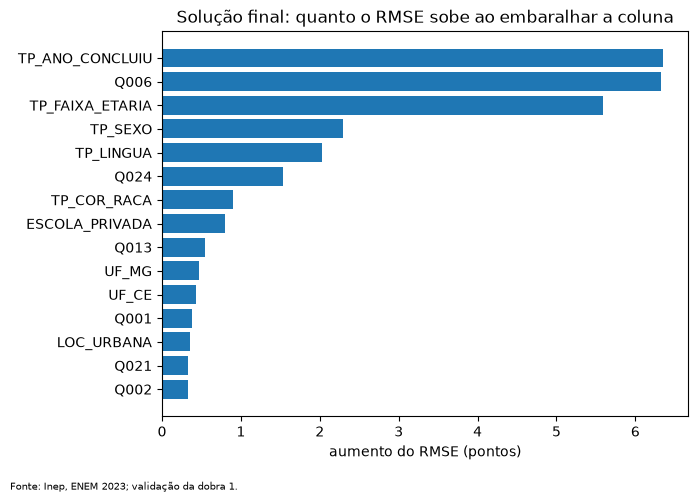

ESCOLA_PRIVADA     0.80
TP_COR_RACA        0.90
Q024               1.53
TP_LINGUA          2.02
TP_SEXO            2.29
TP_FAIXA_ETARIA    5.59
Q006               6.33
TP_ANO_CONCLUIU    6.35


In [14]:
# importância de cada coluna na solução final (por permutação, treino e validação da dobra 1; 5 mil pessoas da validação)
from sklearn.inspection import permutation_importance

tr1, va1 = next(iter(dobras.split()))
m1 = clone(pipe_final())
m1.fit(X[COLS].iloc[tr1], y.iloc[tr1], **({} if PESO_FINAL is None else {"regressor__sample_weight": PESO_FINAL(y.iloc[tr1].to_numpy())}))
s5 = np.random.default_rng(SEMENTE).choice(va1, min(5000, len(va1)), replace=False)
pi = permutation_importance(m1, X[COLS].iloc[s5], y.iloc[s5], scoring="neg_root_mean_squared_error", n_repeats=3, random_state=SEMENTE)
imp = pd.Series(pi.importances_mean, index=COLS).sort_values()
plt.figure(figsize=(7, 5))
plt.barh(imp.tail(15).index, imp.tail(15).values)
plt.title("Solução final: quanto o RMSE sobe ao embaralhar a coluna")
plt.xlabel("aumento do RMSE (pontos)")
plt.figtext(0.01, 0.01, "Fonte: Inep, ENEM 2023; validação da dobra 1.", fontsize=7)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig(FIG / "importancia_solucao_final.png", dpi=150)
plt.show()
print(imp.tail(8).round(2).to_string())

## 8. Curva de aprendizado da solução final

Seguindo o enunciado: em **cada uma das 3 dobras** a validação fica fixa e o treino da dobra é embaralhado com a semente 42; usamos os primeiros **10%, 25%, 50%, 75% e 100%** das linhas (subconjuntos progressivos). Para cada tamanho, todo o pipeline é **reajustado** (fusão, seleção e regressor) com os hiperparâmetros já escolhidos, e medimos o RMSE no próprio subconjunto de treino e na validação da dobra. Não se usa o teste. O resultado vai sendo salvo em `resultados/tabelas/curva_aprendizado.csv` (se o notebook parar, ele continua de onde parou).

dobra 1, 10% (143,596 linhas): treino 102.91 | validação 106.59 | 14 s


dobra 1, 25% (358,990 linhas): treino 103.59 | validação 106.18 | 31 s


dobra 1, 50% (717,980 linhas): treino 104.05 | validação 105.93 | 75 s


dobra 1, 75% (1,076,970 linhas): treino 104.83 | validação 105.88 | 83 s


dobra 1, 100% (1,435,960 linhas): treino 104.72 | validação 105.78 | 140 s


dobra 2, 10% (143,596 linhas): treino 102.13 | validação 106.56 | 18 s


... (5 outputs left out)

dobra 3, 25% (358,990 linhas): treino 103.95 | validação 106.46 | 29 s


dobra 3, 50% (717,980 linhas): treino 104.32 | validação 106.23 | 62 s


dobra 3, 75% (1,076,971 linhas): treino 104.42 | validação 106.13 | 95 s


dobra 3, 100% (1,435,961 linhas): treino 104.88 | validação 106.10 | 102 s


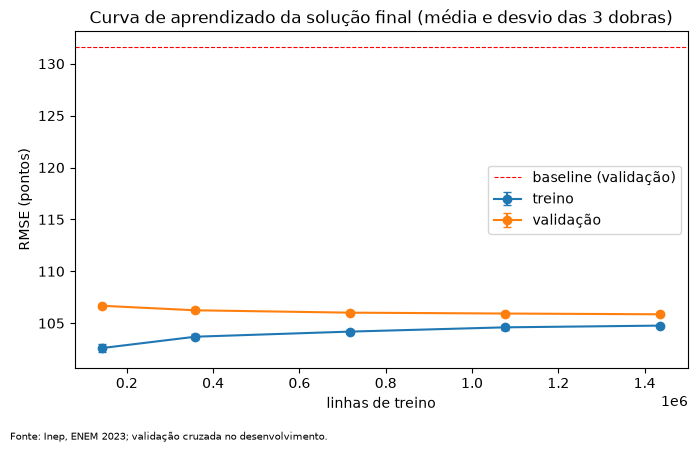

,n_treino,treino,treino_dp,validacao,validacao_dp,lacuna
fracao,,,,,,
0.10,143596.0,102.612672,0.422,106.678096,0.174,4.065425
0.25,358990.0,103.700449,0.217,106.246047,0.194,2.545598
0.50,717980.0,104.193541,0.131,106.017048,0.188,1.823507
0.75,1076970.666667,104.60395,0.210,105.932885,0.176,1.328935
1.00,1435960.666667,104.7699,0.098,105.861443,0.207,1.091544


In [15]:
TAMANHOS = [0.10, 0.25, 0.50, 0.75, 1.00]
ARQ_CURVA = TAB / "curva_aprendizado.csv"
curva = pd.read_csv(ARQ_CURVA) if ARQ_CURVA.exists() else pd.DataFrame(columns=["dobra", "fracao", "n_treino", "RMSE_treino", "RMSE_validacao", "tempo_s"])
Xc = X[COLS]
for k, (tr, va) in enumerate(dobras.split(), 1):
    ordem = np.random.default_rng(SEMENTE).permutation(tr)            # treino da dobra embaralhado; cada tamanho é o começo da lista
    for f in TAMANHOS:
        if ((curva["dobra"] == k) & (curva["fracao"] == f)).any():
            continue
        idx = ordem[: int(round(f * len(tr)))]
        t0 = time.time()
        m = clone(pipe_final())
        m.fit(Xc.iloc[idx], y.iloc[idx], **({} if PESO_FINAL is None else {"regressor__sample_weight": PESO_FINAL(y.iloc[idx].to_numpy())}))
        linha = {"dobra": k, "fracao": f, "n_treino": len(idx),
                 "RMSE_treino": mean_squared_error(y.iloc[idx], m.predict(Xc.iloc[idx])) ** 0.5,
                 "RMSE_validacao": mean_squared_error(y.iloc[va], m.predict(Xc.iloc[va])) ** 0.5, "tempo_s": time.time() - t0}
        curva = pd.concat([curva, pd.DataFrame([linha])], ignore_index=True)
        curva.to_csv(ARQ_CURVA, index=False)
        print(f"dobra {k}, {f:.0%} ({len(idx):,} linhas): treino {linha['RMSE_treino']:.2f} | validação {linha['RMSE_validacao']:.2f} | {linha['tempo_s']:.0f} s")

resumo_curva = curva.groupby("fracao").agg(n_treino=("n_treino", "mean"), treino=("RMSE_treino", "mean"), treino_dp=("RMSE_treino", "std"),
                                           validacao=("RMSE_validacao", "mean"), validacao_dp=("RMSE_validacao", "std"))
resumo_curva["lacuna"] = resumo_curva["validacao"] - resumo_curva["treino"]
resumo_curva.to_csv(TAB / "curva_aprendizado_resumo.csv")
plt.figure(figsize=(7, 4.5))
plt.errorbar(resumo_curva["n_treino"], resumo_curva["treino"], resumo_curva["treino_dp"], marker="o", capsize=3, label="treino")
plt.errorbar(resumo_curva["n_treino"], resumo_curva["validacao"], resumo_curva["validacao_dp"], marker="o", capsize=3, label="validação")
plt.axhline(exp.loc["F_baseline_cv", "RMSE_media"], color="red", ls="--", lw=0.8, label="baseline (validação)")
plt.title("Curva de aprendizado da solução final (média e desvio das 3 dobras)")
plt.xlabel("linhas de treino")
plt.ylabel("RMSE (pontos)")
plt.legend()
plt.figtext(0.01, 0.01, "Fonte: Inep, ENEM 2023; validação cruzada no desenvolvimento.", fontsize=7)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig(FIG / "curva_aprendizado.png", dpi=150)
plt.show()
resumo_curva.round(3)

## 9. Teste final (uma única vez)

A solução está fixada (seções 1 a 8). Agora, nos **80% de desenvolvimento completos**, ajustamos o baseline, a regressão linear sem regularização e a solução final (o `Pipeline` reaprende fusão, seleção e regressor; o baseline recalcula a média). Só depois lemos a nota do teste e avaliamos os três **nos mesmos participantes**. Nada daqui volta para a escolha de features, técnicas ou hiperparâmetros.

Faixas de nota e grupos foram definidos no desenvolvimento (seção 5 e abaixo) e mantidos aqui. Grupos: **região e UF da prova** (localização), **faixa de renda** (Q006, em salários mínimos de 2023, R$ 1.320) e **tipo de escola**.

In [16]:
Xd, Xt = X[COLS], X_teste[COLS]
modelos = {
    "baseline": montar(DummyRegressor(strategy="mean")),
    "regressao_linear": montar(LinearRegression(), fusao=FUSAO, padronizar=True),
    "final": pipe_final(),
}
ajustados, t_fit = {}, {}
for nome, pipe in modelos.items():
    t0 = time.time()
    ajuste = {"regressor__sample_weight": PESO_FINAL(y.to_numpy())} if (nome == "final" and PESO_FINAL is not None) else {}
    ajustados[nome] = clone(pipe).fit(Xd, y, **ajuste)
    t_fit[nome] = time.time() - t0
    joblib.dump(ajustados[nome], MODELOS / f"{nome}_avaliacao_final.joblib")
    print(f"{nome}: ajustado nos {len(y):,} do desenvolvimento em {t_fit[nome]:.0f} s")

baseline: ajustado nos 2,153,941 do desenvolvimento em 0 s


regressao_linear: ajustado nos 2,153,941 do desenvolvimento em 4 s


final: ajustado nos 2,153,941 do desenvolvimento em 165 s


In [17]:
# só agora a nota do teste é lida
y_teste = pd.read_csv(PROC / "dataset_3_escola_features.csv", usecols=[ALVO])[ALVO][~em_dev].reset_index(drop=True)
if SMOKE:
    y_teste = y_teste.iloc[amostra_t].reset_index(drop=True)
assert len(y_teste) == len(Xt)

previsoes = pd.DataFrame({"NU_INSCRICAO": ids_teste, "nota_observada": y_teste})
t_pred = {}
for nome, m in ajustados.items():
    t0 = time.time()
    previsoes[f"previsao_{nome}"] = m.predict(Xt).round(2)
    t_pred[nome] = time.time() - t0
previsoes.to_csv(RES / "previsoes_teste.csv", index=False)

linhas_teste = {}
for nome in ajustados:
    r = metricas(y_teste, previsoes[f"previsao_{nome}"])
    linhas_teste[nome] = {**r, "tempo_ajuste_s": t_fit[nome], "tempo_previsao_s": t_pred[nome]}
    gravar(f"T_{nome}", secao="9 teste final", hipotese="Avaliação única da solução final, fixada só com o desenvolvimento.", features=f"{Xt.shape[1]} colunas",
           preparacao=DESC_PREP if nome == "final" else ("nenhuma" if nome == "baseline" else "padronização"),
           modelo={"baseline": "DummyRegressor(mean)", "regressao_linear": "LinearRegression (sem regularização)", "final": "HistGradientBoosting (hiperparâmetros da busca)"}[nome],
           parametros=str(PARAMS_BUSCA) if nome == "final" else "", avaliado=f"teste ({len(y_teste):,} participantes)", n_features=Xt.shape[1],
           RMSE_media=r["RMSE"], MAE_media=r["MAE"], R2_media=r["R2"], tempo_s=t_fit[nome],
           conclusao="Resultado de teste; separado da média da validação cruzada.")
teste_tab = pd.DataFrame(linhas_teste).T
teste_tab.round(3)

,RMSE,MAE,R2,tempo_ajuste_s,tempo_previsao_s
baseline,131.703,107.636,-0.000,0.002,0.002
regressao_linear,108.863,84.888,0.317,3.565,0.166
final,105.815,82.004,0.354,164.523,4.834


In [18]:
# tabela comparativa: validação cruzada (média ± desvio) separada do teste
cvt = exp.loc[["F_baseline_cv", "F_regressao_linear_cv", "F_final_cv"]]
tabela_final = pd.DataFrame({
    "modelo": ["Baseline (média)", "Regressão linear (sem regularização)", "Solução final (Gradient Boosting)"],
    "CV RMSE": [f"{r.RMSE_media:.2f} ± {r.RMSE_desvio:.2f}" for r in cvt.itertuples()],
    "CV MAE": [f"{r.MAE_media:.2f} ± {r.MAE_desvio:.2f}" for r in cvt.itertuples()],
    "CV R²": [f"{r.R2_media:.3f} ± {r.R2_desvio:.3f}" for r in cvt.itertuples()],
    "CV tempo/dobra (s)": [f"{r.tempo_s:.0f}" for r in cvt.itertuples()],
    "Teste RMSE": [f"{teste_tab.loc[n, 'RMSE']:.2f}" for n in ajustados],
    "Teste MAE": [f"{teste_tab.loc[n, 'MAE']:.2f}" for n in ajustados],
    "Teste R²": [f"{teste_tab.loc[n, 'R2']:.3f}" for n in ajustados],
    "Teste ajuste (s)": [f"{t_fit[n]:.0f}" for n in ajustados],
})
tabela_final.to_csv(TAB / "tabela_final_cv_e_teste.csv", index=False)
tabela_final

,modelo,CV RMSE,CV MAE,CV R²,CV tempo/dobra (s),Teste RMSE,Teste MAE,Teste R²,Teste ajuste (s)
0,Baseline (média),131.63 ± 0.16,107.58 ± 0.06,-0.000 ± 0.000,0,131.70,107.64,-0.000,0
1,Regressão linear (sem regularização),108.87 ± 0.16,84.86 ± 0.04,0.316 ± 0.001,3,108.86,84.89,0.317,4
2,Solução final (Gradient Boosting),105.86 ± 0.17,82.02 ± 0.05,0.353 ± 0.001,91,105.81,82.00,0.354,165


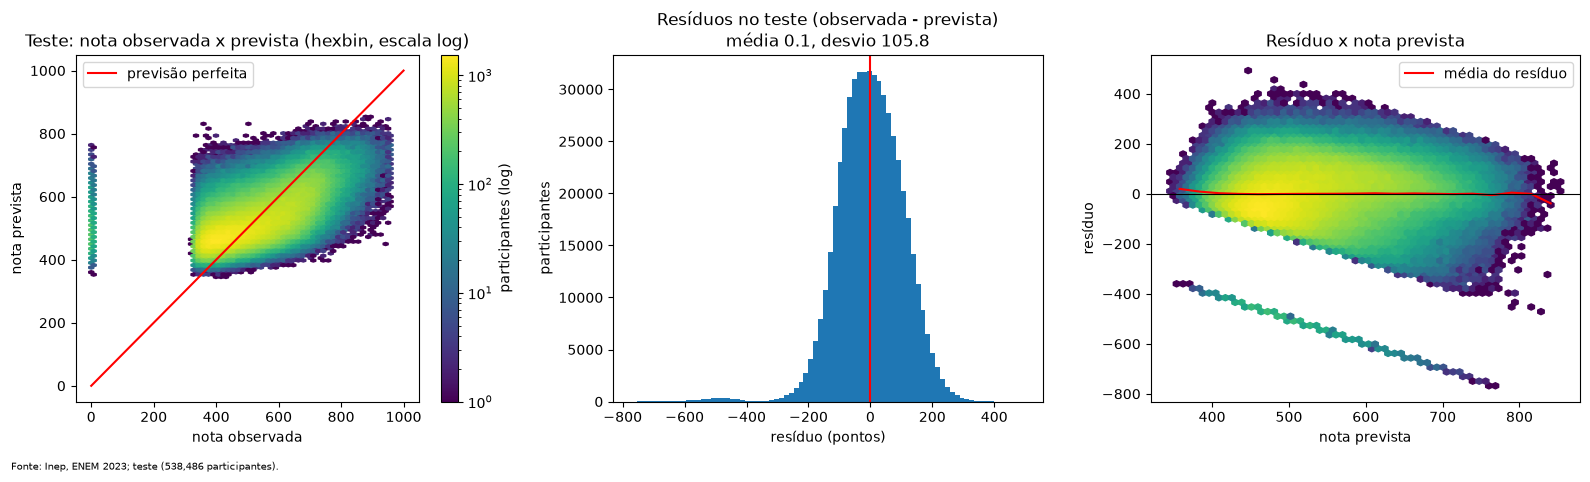

In [19]:
# nota observada x prevista no teste (agregada em células hexagonais: 538 mil pontos não cabem num scatter) e resíduos
real, prev = previsoes["nota_observada"].to_numpy(), previsoes["previsao_final"].to_numpy()
res_ = real - prev
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
hb = ax[0].hexbin(real, prev, gridsize=60, bins="log", cmap="viridis", mincnt=1)
ax[0].plot([0, 1000], [0, 1000], color="red", label="previsão perfeita")
ax[0].set_title("Teste: nota observada x prevista (hexbin, escala log)")
ax[0].set_xlabel("nota observada")
ax[0].set_ylabel("nota prevista")
ax[0].legend()
plt.colorbar(hb, ax=ax[0], label="participantes (log)")
ax[1].hist(res_, bins=80, color="tab:blue")
ax[1].axvline(0, color="red")
ax[1].set_title(f"Resíduos no teste (observada - prevista)\nmédia {res_.mean():.1f}, desvio {res_.std():.1f}")
ax[1].set_xlabel("resíduo (pontos)")
ax[1].set_ylabel("participantes")
hb2 = ax[2].hexbin(prev, res_, gridsize=60, bins="log", cmap="viridis", mincnt=1)
cortes = pd.cut(prev, 20)
medias = pd.Series(res_).groupby(cortes, observed=True).mean()
ax[2].plot([i.mid for i in medias.index], medias.values, color="red", label="média do resíduo")
ax[2].axhline(0, color="black", lw=0.8)
ax[2].set_title("Resíduo x nota prevista")
ax[2].set_xlabel("nota prevista")
ax[2].set_ylabel("resíduo")
ax[2].legend()
fig.text(0.01, 0.01, f"Fonte: Inep, ENEM 2023; teste ({len(real):,} participantes).", fontsize=7)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG / "teste_real_previsto_residuos.png", dpi=150)
plt.show()

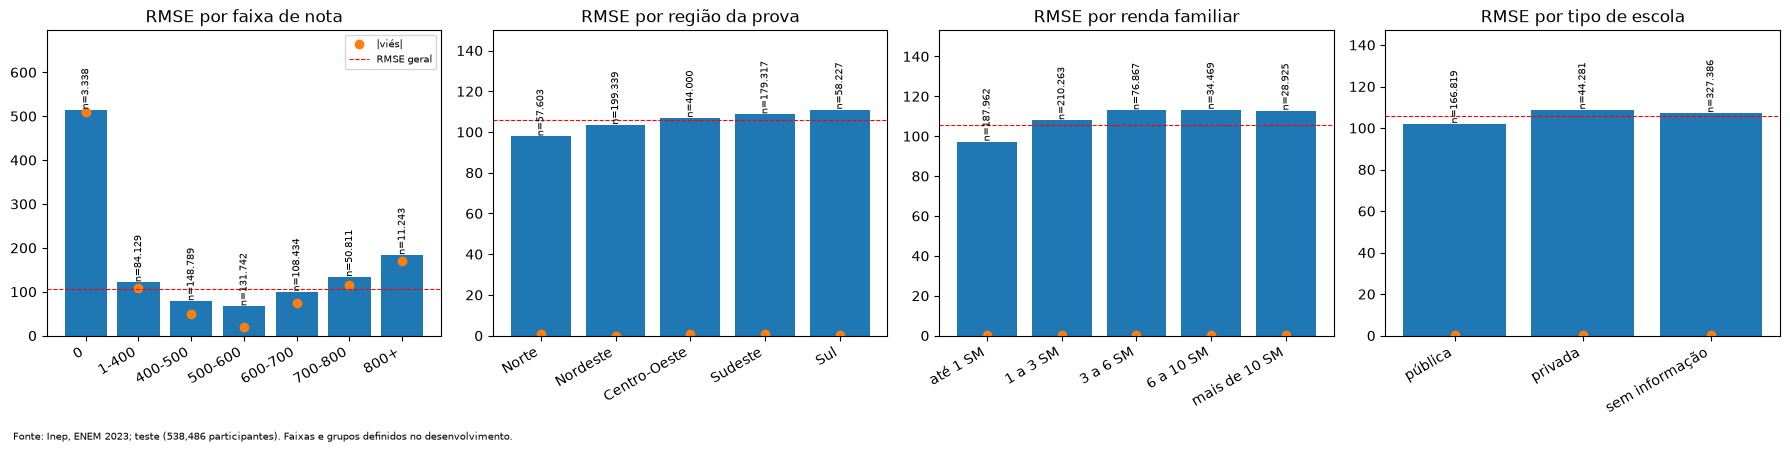

,tipo,n,nota_media,RMSE,MAE,vies,R2
grupo,,,,,,,
0,faixa de nota,3338,0.00,515.03,510.37,-510.37,0.00
1-400,faixa de nota,84129,369.23,121.75,108.59,-108.51,-38.13
400-500,faixa de nota,148789,449.49,78.82,60.80,-49.82,-6.49
500-600,faixa de nota,131742,548.70,67.05,54.79,18.58,-4.41
600-700,faixa de nota,108434,647.50,100.28,84.60,74.24,-11.36
700-800,faixa de nota,50811,738.75,133.86,117.26,115.47,-23.46
800+,faixa de nota,11243,844.12,183.68,171.02,171.00,-25.00
Norte,região da prova,57603,487.90,97.87,75.19,-0.61,0.29
Nordeste,região da prova,199339,511.55,103.52,80.83,0.01,0.33


In [20]:
# erros por faixa de nota e por grupos (tamanho de cada grupo no gráfico e na tabela)
def erros_por(grupo, nome, ordem=None):
    d = pd.DataFrame({"grupo": grupo.to_numpy(), "erro": res_, "real": real, "prev": prev})
    g = d.groupby("grupo", observed=True)
    t = pd.DataFrame({"n": g.size(), "nota_media": g["real"].mean(), "RMSE": g["erro"].apply(lambda e: np.sqrt((e ** 2).mean())),
                      "MAE": g["erro"].apply(lambda e: e.abs().mean()), "vies": g["erro"].mean()})
    t["R2"] = g.apply(lambda s: r2_score(s["real"], s["prev"]) if len(s) > 1 else np.nan, include_groups=False)
    if ordem is not None:
        t = t.reindex(ordem)
    t.insert(0, "tipo", nome)
    return t


REGIAO = {**{u: "Norte" for u in ["AC", "AP", "AM", "PA", "RO", "RR", "TO"]}, **{u: "Nordeste" for u in ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"]},
          **{u: "Centro-Oeste" for u in ["DF", "GO", "MT", "MS"]}, **{u: "Sudeste" for u in ["ES", "MG", "RJ", "SP"]}, **{u: "Sul" for u in ["PR", "RS", "SC"]}}
q6 = X_teste["Q006"].astype(int)
renda = pd.cut(q6, [-1, 1, 5, 8, 12, 16], labels=["até 1 SM", "1 a 3 SM", "3 a 6 SM", "6 a 10 SM", "mais de 10 SM"])
escola = pd.Series(np.where(X_teste["ESCOLA_PUBLICA"] == 1, "pública", np.where(X_teste["ESCOLA_PRIVADA"] == 1, "privada", "sem informação")))
faixa = pd.cut(pd.Series(real), FAIXAS, labels=ROT_FAIXAS)

tab_grupos = pd.concat([erros_por(faixa, "faixa de nota", ROT_FAIXAS), erros_por(uf_teste.map(REGIAO), "região da prova", ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]), erros_por(renda, "renda familiar", ["até 1 SM", "1 a 3 SM", "3 a 6 SM", "6 a 10 SM", "mais de 10 SM"]),
                        erros_por(escola, "tipo de escola", ["pública", "privada", "sem informação"]), erros_por(X_teste["TP_SEXO"].map({0.0: "masculino", 1.0: "feminino"}), "sexo"),
                        erros_por(uf_teste, "UF da prova")])
tab_grupos.to_csv(TAB / "teste_erros_por_grupo.csv")
fig, ax = plt.subplots(1, 4, figsize=(18, 4.5))
for a_, tipo in zip(ax, ["faixa de nota", "região da prova", "renda familiar", "tipo de escola"]):
    t = tab_grupos[tab_grupos["tipo"] == tipo]
    a_.bar(range(len(t)), t["RMSE"], color="tab:blue")
    a_.plot(range(len(t)), t["vies"].abs(), "o", color="tab:orange", label="|viés|")
    for i, (n, v) in enumerate(zip(t["n"], t["RMSE"])):
        a_.text(i, v, f"n={n:,}".replace(",", "."), ha="center", va="bottom", fontsize=7, rotation=90)
    a_.set_xticks(range(len(t)), t.index, rotation=30, ha="right")
    a_.set_title(f"RMSE por {tipo}")
    a_.set_ylim(0, t["RMSE"].max() * 1.35)
    a_.axhline(teste_tab.loc["final", "RMSE"], color="red", ls="--", lw=0.8, label="RMSE geral")
ax[0].legend(fontsize=7)
fig.text(0.01, 0.01, f"Fonte: Inep, ENEM 2023; teste ({len(real):,} participantes). Faixas e grupos definidos no desenvolvimento.", fontsize=7)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG / "teste_erros_por_faixa_e_grupo.png", dpi=150)
plt.show()
tab_grupos[tab_grupos["tipo"] != "UF da prova"].round(2)

## 10. Figuras para o artigo

- **Comparação dos modelos:** validação cruzada inicial de todos os regressores contra o baseline, e os 3 melhores antes e depois da busca (números copiados das saídas dos notebooks 02 e 02-optimized, guardados no `experimentos.csv`).
- **PCA:** variância explicada acumulada (PCA ajustado no treino da dobra 1 do `dataset_1_fundido`, padronizado) e o RMSE com e sem PCA em 2 regressores (notebook 03).

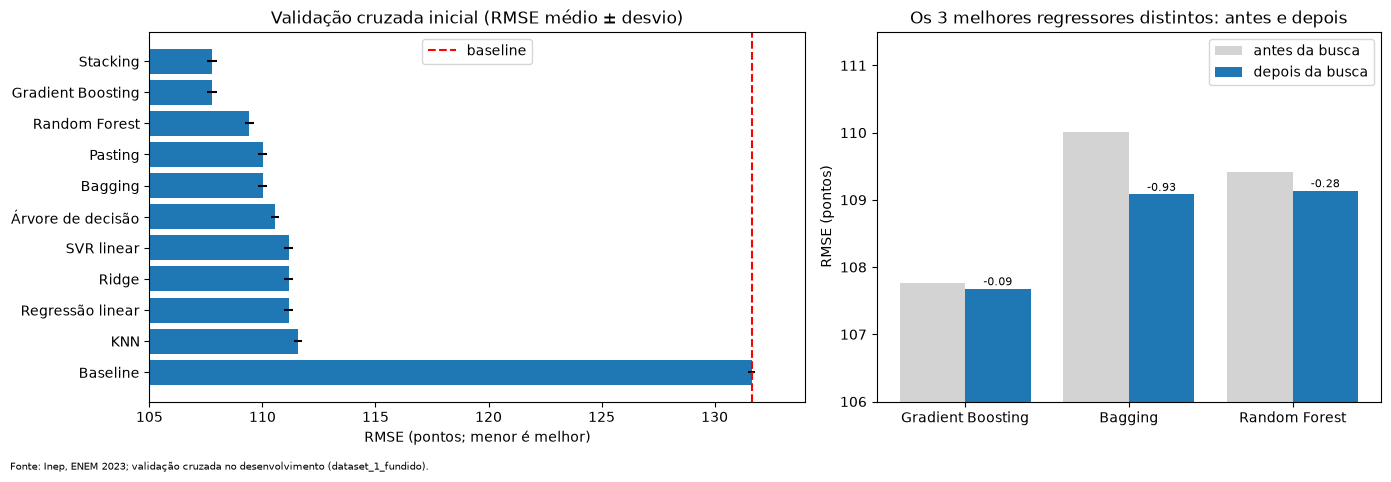

In [21]:
ini = exp[exp.index.str.startswith("H_inicial_")].copy()
ini.index = [i.replace("H_inicial_", "") for i in ini.index]
ini = ini.sort_values("RMSE_media", ascending=False)
top3 = ["Gradient Boosting", "Bagging", "Random Forest"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax[0].barh(ini.index, ini["RMSE_media"].astype(float), xerr=ini["RMSE_desvio"].astype(float).fillna(0), color="tab:blue")
ax[0].axvline(ini.loc["Baseline", "RMSE_media"], color="red", ls="--", label="baseline")
ax[0].set_xlim(105, 134)
ax[0].set_title("Validação cruzada inicial (RMSE médio ± desvio)")
ax[0].set_xlabel("RMSE (pontos; menor é melhor)")
ax[0].legend()
antes = [exp.loc[f"H_inicial_{n}", "RMSE_media"] for n in top3]
depois = [exp.loc[f"H_busca_{n}", "RMSE_media"] for n in top3]
x = np.arange(3)
ax[1].bar(x - 0.2, antes, 0.4, label="antes da busca", color="lightgray")
ax[1].bar(x + 0.2, depois, 0.4, label="depois da busca", color="tab:blue")
for i, (a_, d_) in enumerate(zip(antes, depois)):
    ax[1].text(i + 0.2, d_ + 0.05, f"{d_ - a_:+.2f}", ha="center", fontsize=8)
ax[1].set_xticks(x, top3)
ax[1].set_ylim(106, 111.5)
ax[1].set_title("Os 3 melhores regressores distintos: antes e depois")
ax[1].set_ylabel("RMSE (pontos)")
ax[1].legend()
fig.text(0.01, 0.01, "Fonte: Inep, ENEM 2023; validação cruzada no desenvolvimento (dataset_1_fundido).", fontsize=7)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG / "comparacao_modelos.png", dpi=150)
plt.show()

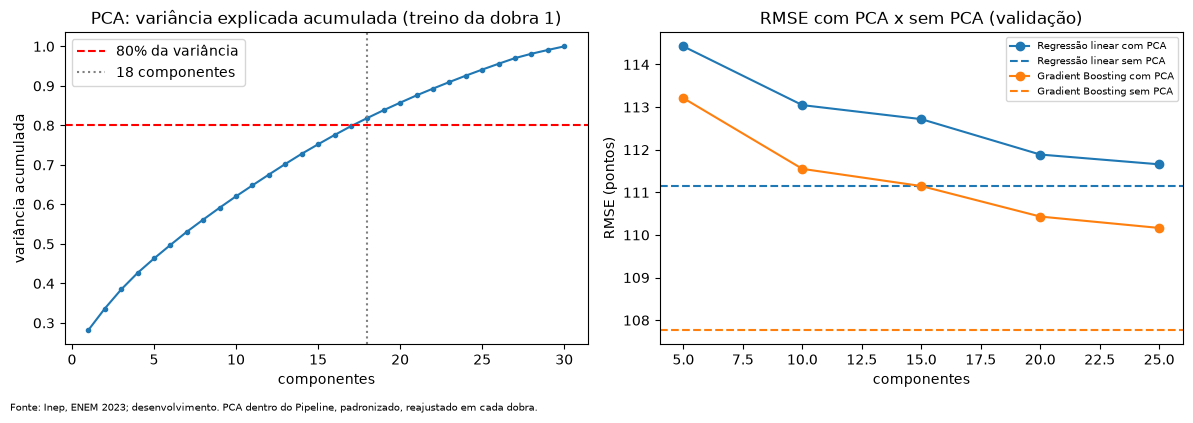

18 componentes (de 30) explicam 80% da variância; nenhum k testado supera o modelo sem PCA.


In [22]:
# PCA: variância explicada acumulada (treino da dobra 1, dataset_1_fundido padronizado) + RMSE com e sem PCA (notebook 03)
from sklearn.decomposition import PCA

d1 = pd.read_csv(PROC / "dataset_1_fundido.csv").drop(columns=ALVO)[em_dev].reset_index(drop=True)
if SMOKE:
    d1 = d1.iloc[amostra].reset_index(drop=True)
Z = StandardScaler().fit_transform(d1.iloc[tr1])
var = np.cumsum(PCA(random_state=SEMENTE).fit(Z).explained_variance_ratio_)
n80 = int(np.argmax(var >= 0.80)) + 1
del d1, Z
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(range(1, len(var) + 1), var, marker="o", ms=3)
ax[0].axhline(0.80, color="red", ls="--", label="80% da variância")
ax[0].axvline(n80, color="gray", ls=":", label=f"{n80} componentes")
ax[0].set_title("PCA: variância explicada acumulada (treino da dobra 1)")
ax[0].set_xlabel("componentes")
ax[0].set_ylabel("variância acumulada")
ax[0].legend()
pc = exp[exp.index.str.startswith("H_pca_")]
for nome, cor in [("Regressão linear", "tab:blue"), ("Gradient Boosting", "tab:orange")]:
    t = pc[pc["modelo"] == nome]
    comps = [c for c in ["5", "10", "15", "20", "25"]]
    ax[1].plot([int(c) for c in comps], [t.loc[f"H_pca_{nome}_{c}", "RMSE_media"] for c in comps], marker="o", color=cor, label=f"{nome} com PCA")
    ax[1].axhline(t.loc[f"H_pca_{nome}_sem PCA", "RMSE_media"], color=cor, ls="--", label=f"{nome} sem PCA")
ax[1].set_title("RMSE com PCA x sem PCA (validação)")
ax[1].set_xlabel("componentes")
ax[1].set_ylabel("RMSE (pontos)")
ax[1].legend(fontsize=7)
fig.text(0.01, 0.01, "Fonte: Inep, ENEM 2023; desenvolvimento. PCA dentro do Pipeline, padronizado, reajustado em cada dobra.", fontsize=7)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG / "pca_variancia_e_rmse.png", dpi=150)
plt.show()
print(f"{n80} componentes (de {len(var)}) explicam 80% da variância; nenhum k testado supera o modelo sem PCA.")

## Resumo de tudo o que foi registrado

`resultados/experimentos.csv` tem uma linha por experimento (histórico dos notebooks 02 e 03 + seções 1 a 9 deste), com hipótese, features, preparação, modelo, parâmetros, conjunto avaliado, métricas por dobra, média, desvio, tempo e conclusão. As linhas `T_*` são do teste final; as demais, da validação cruzada no desenvolvimento.

In [23]:
exp[["secao", "avaliado", "RMSE_media", "RMSE_desvio", "conclusao"]].astype({"RMSE_media": float, "RMSE_desvio": float}).round(3)

,secao,avaliado,RMSE_media,RMSE_desvio,conclusao
H_inicial_Baseline,02 configuração inicial,validação cruzada (3 dobras) no desenvolvimento,131.634,0.158,"Configuração inicial, antes das buscas."
H_inicial_Regressão linear,02 configuração inicial,validação cruzada (3 dobras) no desenvolvimento,111.153,0.178,"Configuração inicial, antes das buscas."
H_inicial_Ridge,02 configuração inicial,validação cruzada (3 dobras) no desenvolvimento,111.153,0.178,"Configuração inicial, antes das buscas."
H_inicial_Árvore de decisão,02 configuração inicial,validação cruzada (3 dobras) no desenvolvimento,110.551,0.190,"Configuração inicial, antes das buscas."
H_inicial_KNN,02 configuração inicial,validação cruzada (3 dobras) no desenvolvimento,111.575,0.184,"Configuração inicial, antes das buscas."
...,...,...,...,...,...
F_regressao_linear_cv,7 solução final,validação cruzada (3 dobras) no desenvolvimento,108.868,0.162,
F_final_cv,7 solução final,validação cruzada (3 dobras) no desenvolvimento,105.864,0.169,RMSE -0.161 em relação a S2_com_uf: sem difere...
T_baseline,9 teste final,"teste (538,486 participantes)",131.703,NaN,Resultado de teste; separado da média da valid...
T_regressao_linear,9 teste final,"teste (538,486 participantes)",108.863,NaN,Resultado de teste; separado da média da valid...
